In [1]:
import pandas as pd
from pathlib import Path

In [2]:
driver_train = pd.read_csv("../data/splits/driver_based/train.csv")
driver_val = pd.read_csv("../data/splits/driver_based/val.csv")
driver_test = pd.read_csv("../data/splits/driver_based/test.csv")

print("Train:", driver_train.shape)
print("Val:", driver_val.shape)
print("Test:", driver_test.shape)

Train: (15732, 4)
Val: (3603, 4)
Test: (3089, 4)


## Step 1 — Locate Image Files
Find the original images and create their full file paths.

In [3]:
# Find the folder containing the original images
sample_img = driver_train.iloc[0]["img"]
sample_path = next(Path("../data").rglob(sample_img))

image_root = sample_path.parent.parent

# Add full image paths to training and validation data
for data in [driver_train, driver_val]:
    data["filepath"] = data.apply(
        lambda row: str(
            image_root / row["classname"] / row["img"]
        ),
        axis=1
    )

# Verify the first image exists
print("Image root:", image_root)
print("First image exists:", Path(driver_train.iloc[0]["filepath"]).is_file())

driver_train.head()

Image root: ../data/raw/state-farm-distracted-driver-detection/imgs/train
First image exists: True


,subject,classname,img,split,filepath
0,p002,c0,img_44733.jpg,train,../data/raw/state-farm-distracted-driver-detec...
1,p002,c0,img_72999.jpg,train,../data/raw/state-farm-distracted-driver-detec...
2,p002,c0,img_25094.jpg,train,../data/raw/state-farm-distracted-driver-detec...
3,p002,c0,img_69092.jpg,train,../data/raw/state-farm-distracted-driver-detec...
4,p002,c0,img_92629.jpg,train,../data/raw/state-farm-distracted-driver-detec...


## Step 2 — Image Preprocessing and HOG Feature Extraction
Convert images to grayscale, resize them to 64×64,
and extract HOG features for classification.

In [4]:
from skimage.io import imread
from skimage.color import rgb2gray
from skimage.transform import resize
from skimage.feature import hog

# Load one training image
image = imread(driver_train.iloc[0]["filepath"])

# Convert to grayscale
gray = rgb2gray(image)

# Resize to 64x64 pixels
gray = resize(gray, (64, 64), anti_aliasing=True)

# Extract HOG features
features, hog_image = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

print("Image shape:", gray.shape)
print("HOG features:", features.shape)

Image shape: (64, 64)
HOG features: (1764,)


## Step 3 — Visualize HOG Features

Compare the original driver image with its HOG feature visualization.

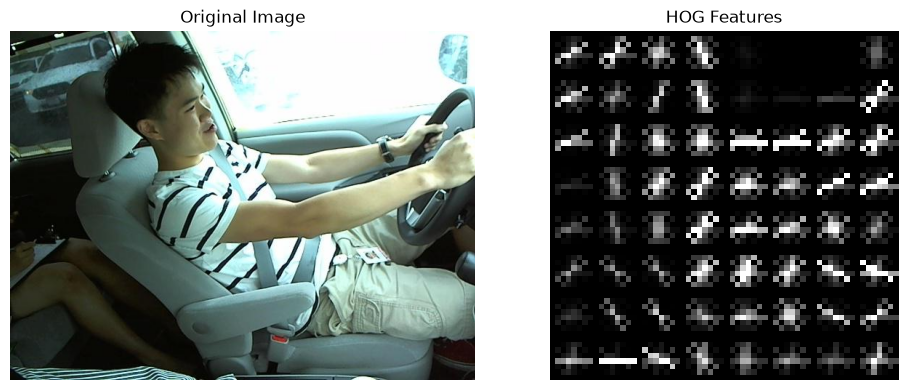

In [5]:
import matplotlib.pyplot as plt
from skimage import exposure

# Improve visibility of HOG edges
hog_display = exposure.rescale_intensity(
    hog_image, in_range=(0, 0.1)
)

# Display original image and HOG visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(hog_display, cmap="gray")
axes[1].set_title("HOG Features")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Step 4 — Extract HOG Features from Training Data

Convert each image into a fixed-length feature vector for SVM training.

In [6]:
def extract_hog(image_path):
    # Load image
    image = imread(image_path)

    # Convert to grayscale and resize
    gray = rgb2gray(image)
    gray = resize(gray, (64, 64), anti_aliasing=True)

    # Extract numerical HOG features
    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2)
    )

    return features

# Test on one image
sample_features = extract_hog(driver_train.iloc[0]["filepath"])

print("Feature vector shape:", sample_features.shape)

Feature vector shape: (1764,)


## Step 5 — Build HOG Feature Dataset

Extract HOG features from all training and validation images.

In [ ]:
import numpy as np
from tqdm.auto import tqdm

def build_features(data):
    # Extract HOG features from each image
    X = np.array([
        extract_hog(path)
        for path in tqdm(data["filepath"])
    ])

    # Extract class labels
    y = data["classname"].to_numpy(dtype="U10")

    return X, y


# Build training features
X_train, y_train = build_features(driver_train)

# Build validation features
X_val, y_val = build_features(driver_val)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

  0%|          | 0/15732 [00:00<?, ?it/s]

  0%|          | 0/3603 [00:00<?, ?it/s]

Training: (15732, 1764)
Validation: (3603, 1764)


## Step 6 — Save HOG Features
Save training and validation features as NumPy files for reuse.


In [11]:
from pathlib import Path
import numpy as np

# Create folder for extracted features
feature_dir = Path("../data/processed/hog/driver_based")
feature_dir.mkdir(parents=True, exist_ok=True)

# Save features
np.save(feature_dir / "X_train.npy", X_train)
np.save(feature_dir / "X_val.npy", X_val)

# Save corresponding class labels
np.save(feature_dir / "y_train.npy", y_train.astype("U10"))
np.save(feature_dir / "y_val.npy", y_val.astype("U10"))
print("HOG features and labels saved successfully!")

HOG features and labels saved successfully!


## Step 7 — Train HOG + SVM Baseline

Use StandardScaler and LinearSVC to train a classical
image classification model.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
import numpy as np

# Load saved HOG features and labels
feature_dir = Path("../data/processed/hog/driver_based")

X_train = np.load(feature_dir / "X_train.npy")
y_train = np.load(feature_dir / "y_train.npy")

X_val = np.load(feature_dir / "X_val.npy")
y_val = np.load(feature_dir / "y_val.npy")

# Create scaling + classification pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        C=1.0,
        max_iter=10000,
        random_state=42
    ))
])

# Train the model
pipeline.fit(X_train, y_train)

print("SVM training completed!")

SVM training completed!


In [13]:
import joblib
from pathlib import Path

# Create a folder for trained models
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the entire fitted pipeline
joblib.dump(
    pipeline,
    model_dir / "hog_svm_driver_based.joblib"
)

print("Trained model saved successfully!")

Trained model saved successfully!


In [14]:
svm = pipeline.named_steps["svm"]

print("Weights:", svm.coef_.shape)
print("Biases:", svm.intercept_.shape)

total_params = svm.coef_.size + svm.intercept_.size
print("Total SVM parameters:", total_params)

Weights: (10, 1764)
Biases: (10,)
Total SVM parameters: 17650


## Step 9 — Evaluate HOG + SVM on Validation Data

Measure accuracy, macro-F1, precision, and recall on unseen drivers.

In [15]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Predict validation labels
y_pred = pipeline.predict(X_val)

# Calculate evaluation metrics
accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average="macro")

print(f"Validation Accuracy: {accuracy:.2%}")
print(f"Validation Macro-F1: {macro_f1:.4f}")

# Show precision, recall, and F1 for each class
print("\nClassification Report:")
print(classification_report(y_val, y_pred, zero_division=0))

Validation Accuracy: 42.52%
Validation Macro-F1: 0.4180

Classification Report:
              precision    recall  f1-score   support

          c0       0.19      0.39      0.26       372
          c1       0.63      0.33      0.43       377
          c2       0.73      0.28      0.40       367
          c3       0.43      0.26      0.33       393
          c4       0.81      0.47      0.59       378
          c5       0.47      0.90      0.62       372
          c6       0.85      0.43      0.57       372
          c7       0.38      0.81      0.52       342
          c8       0.65      0.24      0.36       298
          c9       0.10      0.10      0.10       332

    accuracy                           0.43      3603
   macro avg       0.52      0.42      0.42      3603
weighted avg       0.53      0.43      0.42      3603



## Step 10 — Confusion Matrix

Visualize which driving activities the HOG + SVM
model classifies correctly and incorrectly.

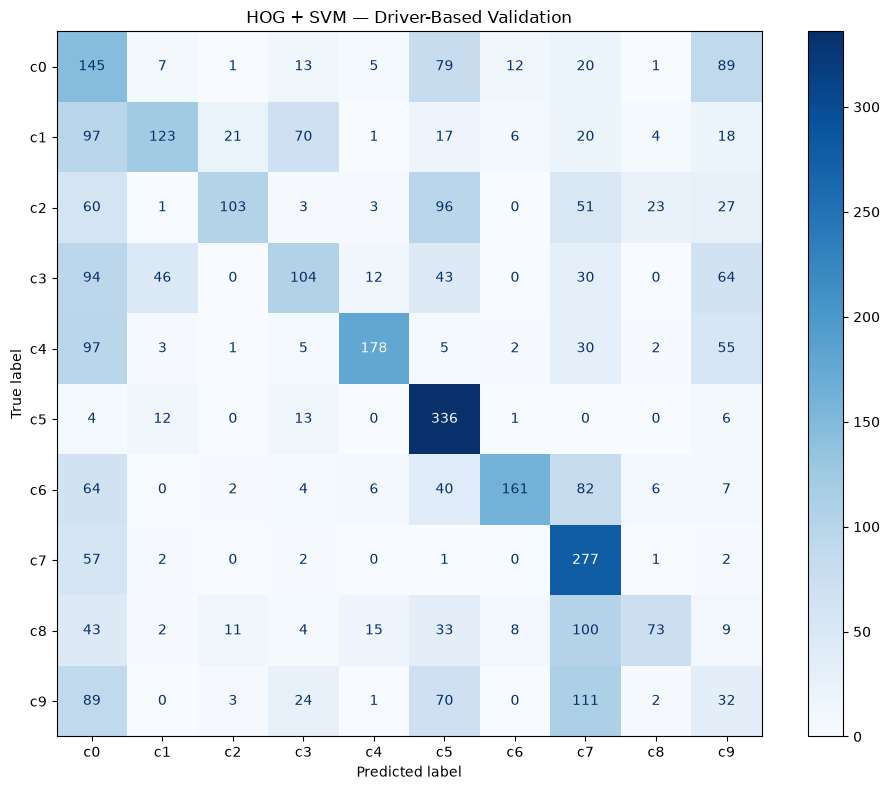

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Display confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    labels=[f"c{i}" for i in range(10)],
    cmap="Blues",
    ax=ax
)

plt.title("HOG + SVM — Driver-Based Validation")
plt.tight_layout()
plt.show()

## Experiment 1 — HOG + Linear SVM

- Split protocol: Driver-based (18/4/4 drivers)
- HOG features: 1,764 per image
- Training samples: 15,732
- Validation samples: 3,603
- SVM: LinearSVC, C=1.0, max_iter=10000
- Random seed: 42
- Training time: 24 minutes 37 seconds (observed notebook runtime)
- Validation accuracy: 42.52%
- Validation macro-F1: 0.4180
- Hardware: Mac CPU

## Step 11 — Qualitative Error Analysis

Investigate why HOG + SVM confuses class c9 with c7.

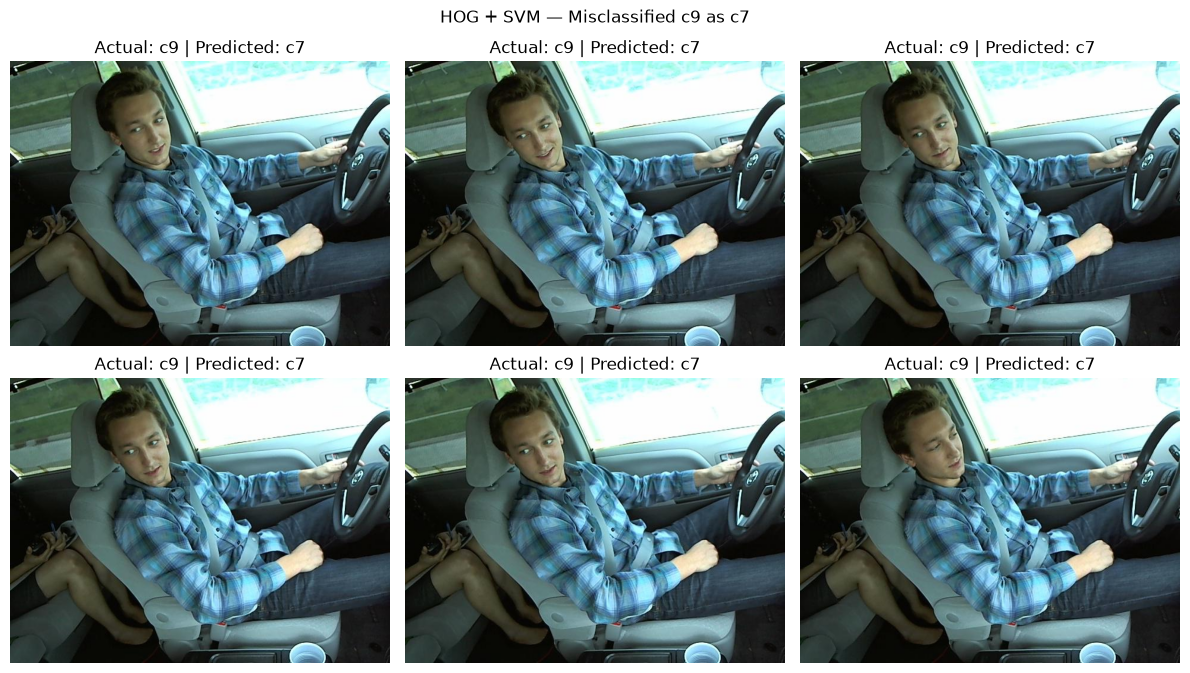

In [17]:
# Find c9 images incorrectly predicted as c7
wrong_indices = np.where(
    (y_val == "c9") & (y_pred == "c7")
)[0][:6]

# Display six misclassified images
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, idx in zip(axes.flat, wrong_indices):
    image = plt.imread(driver_val.iloc[idx]["filepath"])

    ax.imshow(image)
    ax.set_title(f"Actual: {y_val[idx]} | Predicted: {y_pred[idx]}")
    ax.axis("off")

plt.suptitle("HOG + SVM — Misclassified c9 as c7")
plt.tight_layout()
plt.show()

Code	Activity
c0	Safe driving
c1	Texting — right hand
c2	Talking on phone — right hand
c3	Texting — left hand
c4	Talking on phone — left hand
c5	Operating the radio
c6	Drinking
c7	Reaching behind
c8	Hair and makeup
c9	Talking to passenger

## Step 12 — Per-Class Error Analysis


Identify the most common misclassifications for each driving activity.

In [18]:
# Names for each driving activity
class_names = {
    "c0": "Safe driving",
    "c1": "Texting - right",
    "c2": "Phone call - right",
    "c3": "Texting - left",
    "c4": "Phone call - left",
    "c5": "Operating radio",
    "c6": "Drinking",
    "c7": "Reaching behind",
    "c8": "Hair and makeup",
    "c9": "Talking to passenger"
}

# Create a DataFrame of validation predictions
error_df = driver_val.reset_index(drop=True).copy()

error_df["actual"] = y_val
error_df["predicted"] = y_pred

# Calculate errors for each class
results = []

for code, name in class_names.items():
    class_data = error_df[error_df["actual"] == code]

    wrong = class_data[
        class_data["actual"] != class_data["predicted"]
    ]

    # Most frequent incorrect prediction
    most_common = wrong["predicted"].value_counts()

    top_error = (
        most_common.index[0]
        if len(most_common) > 0 else None
    )

    results.append({
        "Class": code,
        "Activity": name,
        "Total": len(class_data),
        "Wrong": len(wrong),
        "Most confused with": top_error,
        "Error rate": round(
            len(wrong) / len(class_data) * 100, 2
        )
    })

error_summary = pd.DataFrame(results)

display(error_summary)

,Class,Activity,Total,Wrong,Most confused with,Error rate
0,c0,Safe driving,372,227,c9,61.02
1,c1,Texting - right,377,254,c0,67.37
2,c2,Phone call - right,367,264,c5,71.93
3,c3,Texting - left,393,289,c0,73.54
4,c4,Phone call - left,378,200,c0,52.91
5,c5,Operating radio,372,36,c3,9.68
6,c6,Drinking,372,211,c7,56.72
7,c7,Reaching behind,342,65,c0,19.01
8,c8,Hair and makeup,298,225,c7,75.50
9,c9,Talking to passenger,332,300,c7,90.36


In [20]:
import matplotlib.pyplot as plt

def show_class_errors(code, n=3):

    # Select incorrectly classified images
    wrong = error_df[
        (error_df["actual"] == code) &
        (error_df["predicted"] != code)
    ]

    if wrong.empty:
        print(f"No errors for {code}")
        return

    print(f"{code}: {class_names[code]}")
    print("Most common wrong predictions:")
    print(wrong["predicted"].value_counts().head(3))

    # Prefer examples from different drivers
    examples = (
        wrong.sample(frac=1, random_state=42)
        .drop_duplicates(subset="subject")
        .head(n)
    )

    fig, axes = plt.subplots(
        1, len(examples),
        figsize=(4 * len(examples), 4)
    )

    axes = np.atleast_1d(axes)

    for ax, (_, row) in zip(axes, examples.iterrows()):
        image = plt.imread(row["filepath"])

        ax.imshow(image)
        ax.set_title(
            f"Actual: {code}\n"
            f"Predicted: {row['predicted']}\n"
            f"Driver: {row['subject']}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

c9: Talking to passenger
Most common wrong predictions:
predicted
c7    111
c0     89
c5     70
Name: count, dtype: int64


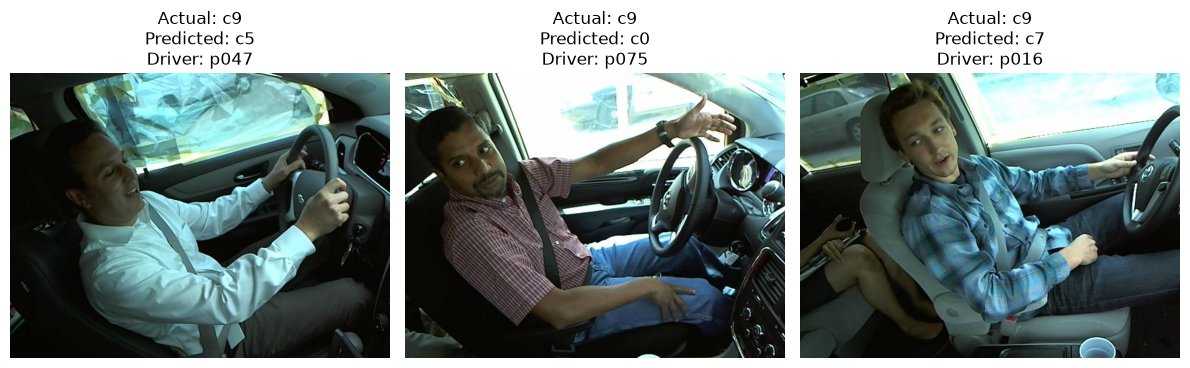

In [21]:
show_class_errors("c9")

c0: Safe driving
Most common wrong predictions:
predicted
c9    89
c5    79
c7    20
Name: count, dtype: int64


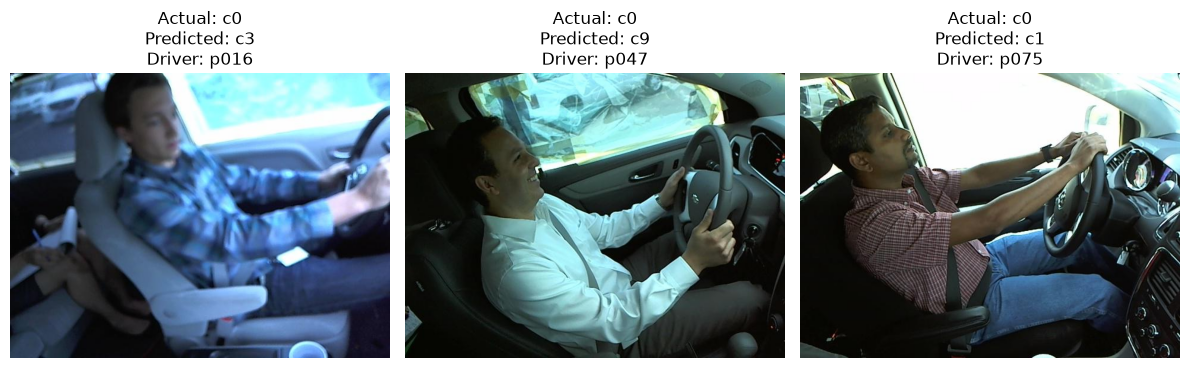

c1: Texting - right
Most common wrong predictions:
predicted
c0    97
c3    70
c2    21
Name: count, dtype: int64


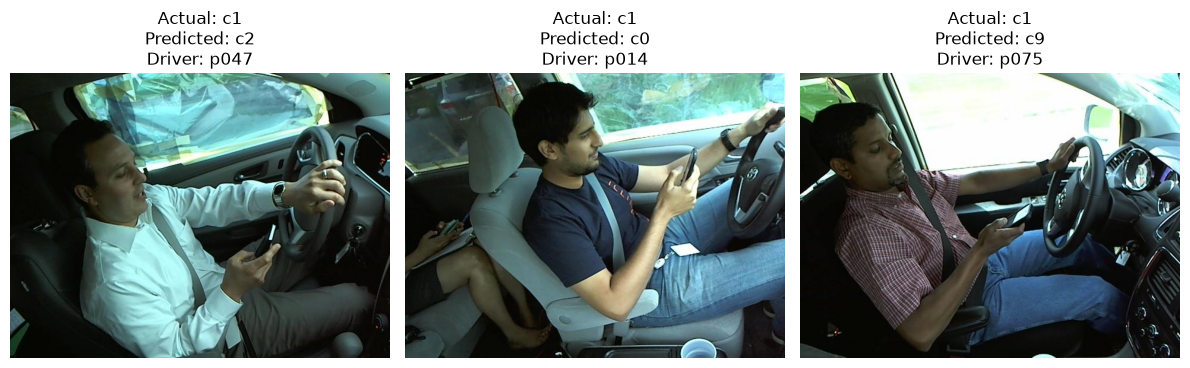

c2: Phone call - right
Most common wrong predictions:
predicted
c5    96
c0    60
c7    51
Name: count, dtype: int64


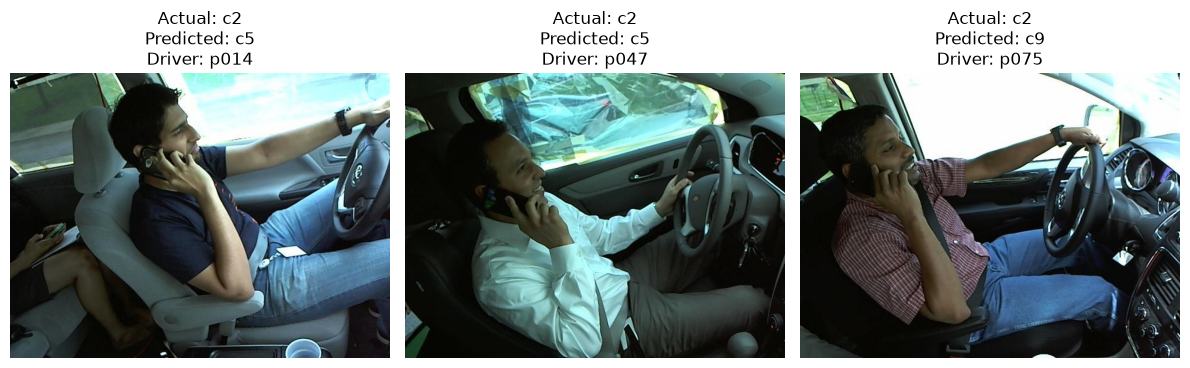

c3: Texting - left
Most common wrong predictions:
predicted
c0    94
c9    64
c1    46
Name: count, dtype: int64


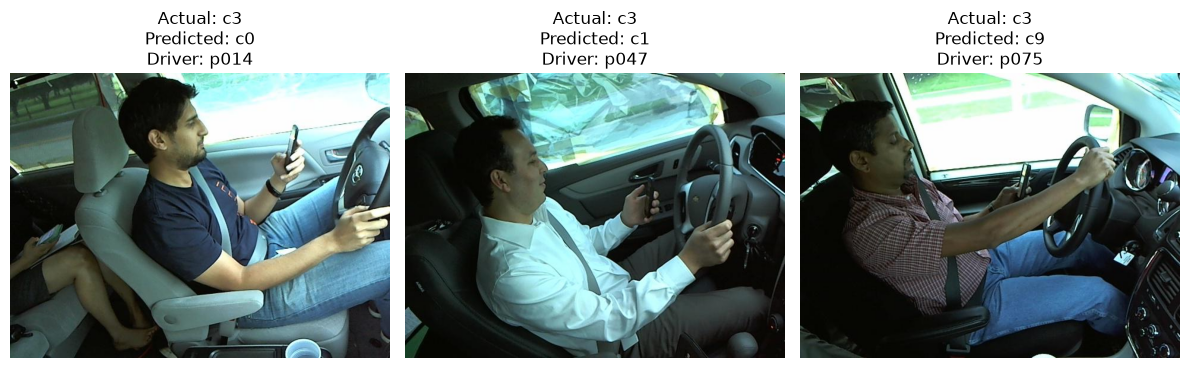

c4: Phone call - left
Most common wrong predictions:
predicted
c0    97
c9    55
c7    30
Name: count, dtype: int64


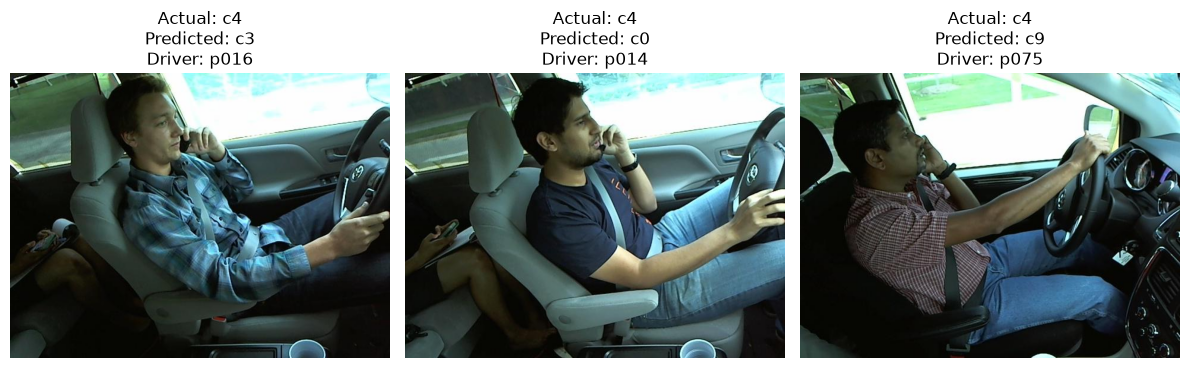

c5: Operating radio
Most common wrong predictions:
predicted
c3    13
c1    12
c9     6
Name: count, dtype: int64


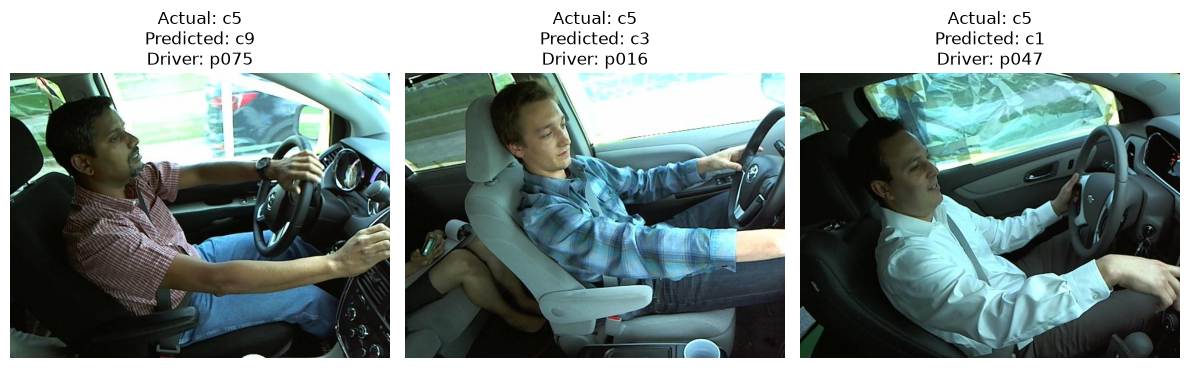

c6: Drinking
Most common wrong predictions:
predicted
c7    82
c0    64
c5    40
Name: count, dtype: int64


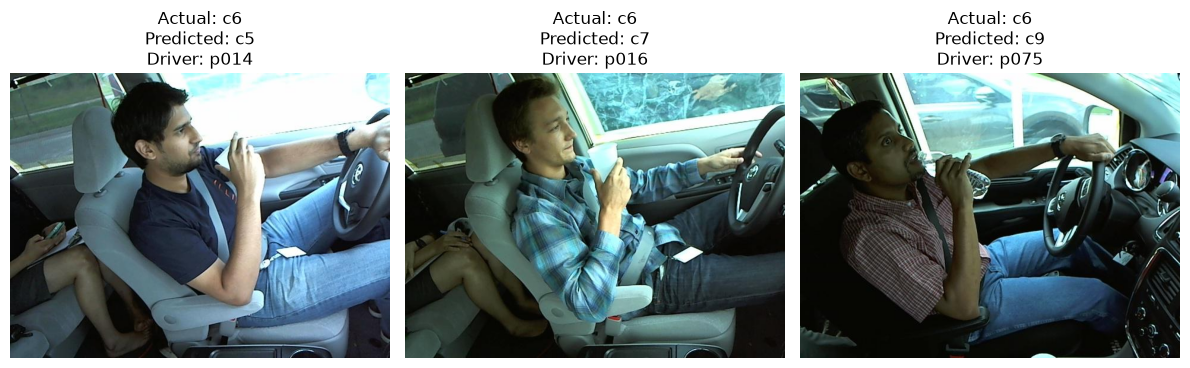

c7: Reaching behind
Most common wrong predictions:
predicted
c0    57
c3     2
c1     2
Name: count, dtype: int64


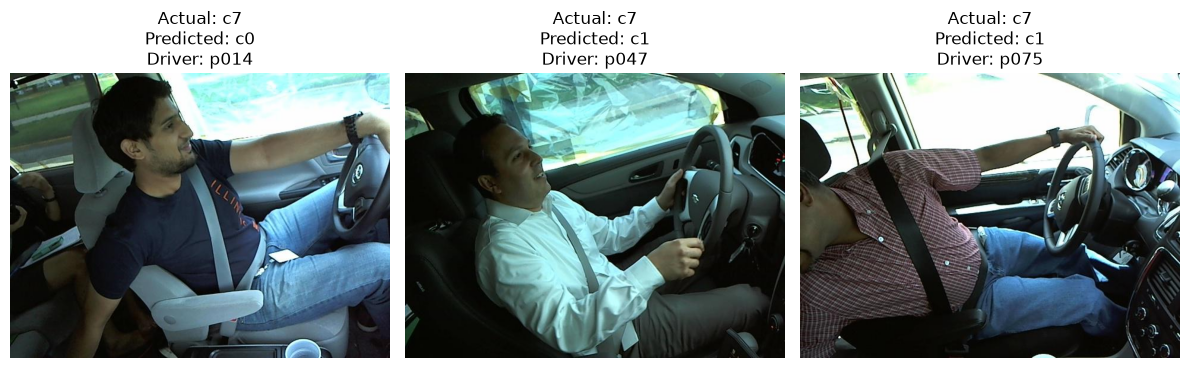

c8: Hair and makeup
Most common wrong predictions:
predicted
c7    100
c0     43
c5     33
Name: count, dtype: int64


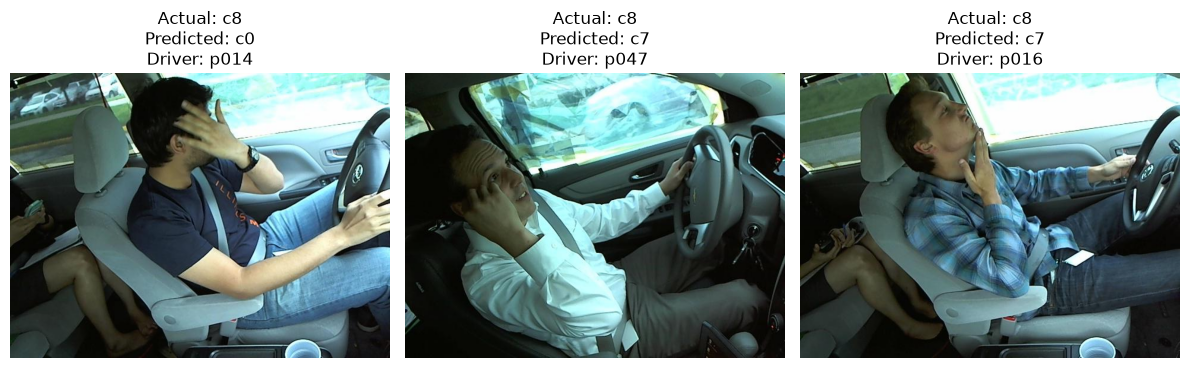

c9: Talking to passenger
Most common wrong predictions:
predicted
c7    111
c0     89
c5     70
Name: count, dtype: int64


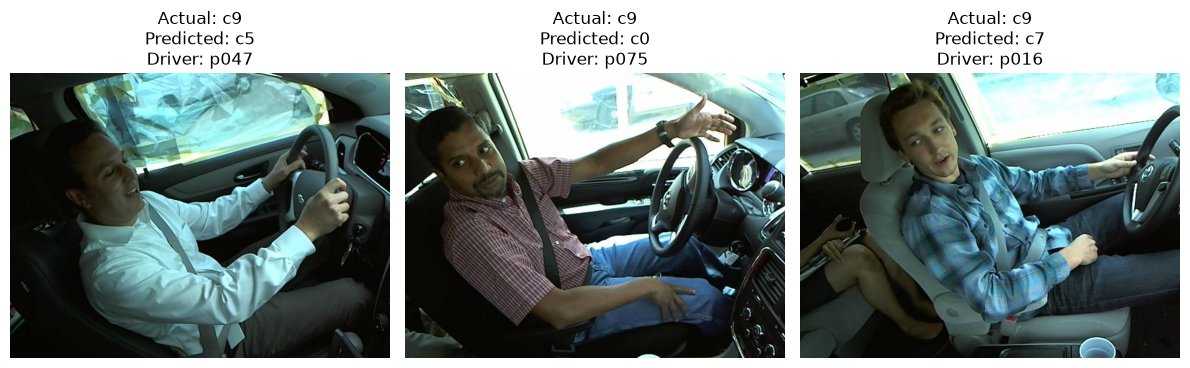

In [22]:
for code in class_names:
    show_class_errors(code)

## Error Analysis — HOG + Linear SVM

**Validation results**
- Accuracy: 42.52%
- Macro-F1: 0.4180
- Validation drivers: 4 unseen drivers

**Initial observations**
- The model recognizes some activities significantly better than others.
- Class c5 has high recall (90%), while c9 has low recall (10%).
- Common errors include c9 being classified as c7 and c8 being classified as c7.
- Several misclassified c9 images are visually similar and belong to the same driver.

**Hypotheses to investigate**
1. HOG captures local edges but cannot explicitly recognize semantic objects such as phones.
2. Reducing images to 64×64 may remove important details.
3. Similar arm and body positions may cause confusion across activities.
4. Driver-specific appearance and backgrounds may affect generalization.

**Limitations**

These observations are based on driver-disjoint validation data. More diverse misclassified examples and additional controlled experiments are needed to establish the causes of the errors.

## Step 15 — Save Evaluation Results

Save validation metrics and predictions for reproducibility
and future model comparison.

In [23]:
import json
from sklearn.metrics import classification_report

# Create results folder
results_dir = Path("../results/hog_svm/driver_based")
results_dir.mkdir(parents=True, exist_ok=True)

# Save overall metrics
metrics = {
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "training_time_seconds": 1477,
    "split": "driver_based",
    "model": "HOG + LinearSVC"
}

with open(results_dir / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# Save class-wise metrics
report = classification_report(
    y_val, y_pred, output_dict=True, zero_division=0
)

pd.DataFrame(report).T.to_csv(
    results_dir / "classification_report.csv"
)

# Save validation predictions
error_df.drop(columns=["filepath"], errors="ignore").to_csv(
    results_dir / "predictions.csv",
    index=False
)

print("Evaluation results saved!")

Evaluation results saved!
